# Linear Algebra for Data Science 2026 — Lab 2, Core A
# Power iteration and inverse iteration

### <div align="right"> &copy; Rostyslav Hryniv, 2026, after V. Kuchynskyi & R. Hryniv, 2023 </div>

## Completed by:
*   First team member
*   Second team member

**Marked at the defence:** Core A is worth 2 points; the starred extensions at the end are one of three routes to the extension point (see the brief).

## Why this core

PageRank (Core B), the smoothing step in a graph neural network, and — later in the course — the leading principal component all need **one** eigenpair of a very large matrix that you can only *multiply by*. Power iteration is the algorithm that needs nothing more than $\mathbf{x}\mapsto A\mathbf{x}$. This core makes you implement it, **predict its speed before you run it**, find out where it breaks, and then use *inverse iteration with a shift* to reach the other eigenvalues.

**Uses:** Lecture 3.1 ($A^n = PD^nP^{-1}$, the Jordan asymptotics $n^k|\lambda|^n$, the role of $\kappa(P)$) and Lecture 3.2 (power iteration, inverse iteration). LU factorisation is a Module 0 prerequisite.

**Rules for this notebook**
* Inside `power_method` and `inverse_iteration` do **not** call `np.linalg.eig`, `np.linalg.eigvals`, `scipy.linalg.eig` or anything that calls them. You may use them elsewhere to *check* your results.
* Never call `np.linalg.inv` anywhere in this notebook. If you need $P^{-1}$ applied to something, solve a system.
* Every number you report must be reproduced by `Restart & Run All`.

In [2]:
import sys, numpy as np, scipy, scipy.linalg as sla, matplotlib
import matplotlib.pyplot as plt
print('python', sys.version.split()[0], '| numpy', np.__version__,
      '| scipy', scipy.__version__, '| matplotlib', matplotlib.__version__)
rng = np.random.default_rng(2026)   # do not change the seed: the defence uses your numbers

python 3.11.9 | numpy 2.4.6 | scipy 1.17.1 | matplotlib 3.11.2


### Two provided helpers

`sin_angle(u, v)` measures how far apart two *directions* are. It ignores length and sign (and, for complex vectors, any unimodular factor), so it is the right error measure for an eigenvector.

`similar_matrix(eigvals, P)` returns $A = P\,\mathrm{diag}(\text{eigvals})\,P^{-1}$ **without** forming $P^{-1}$: from $AP = PD$ we get $P^\top A^\top = (PD)^\top$, which is one linear solve.

In [3]:
def sin_angle(u, v):
    # sine of the angle between span{u} and span{v}; accurate for small angles
    u = u / np.linalg.norm(u)
    v = v / np.linalg.norm(v)
    return np.linalg.norm(u - v * np.vdot(v, u))

def similar_matrix(eigvals, P):
    # A = P diag(eigvals) P^{-1}, computed by one solve instead of an inverse
    PD = P * np.asarray(eigvals)[None, :]          # scales column j of P by eigvals[j]
    return np.linalg.solve(P.T, PD.T).T

def random_orthogonal(n):
    Q, R = np.linalg.qr(rng.standard_normal((n, n)))
    return Q * np.sign(np.diag(R))                  # sign fix: a uniformly random orthogonal Q

---
## 1. Power iteration

### 1.1 The idea, recalled
Let $A$ be a diagonalisable $k\times k$ matrix with eigenvalues ordered so that $|\lambda_1| > |\lambda_2| \ge \dots \ge |\lambda_k|$ (so $\lambda_1$ is real and simple when $A$ is real) and eigenvectors $\mathbf{v}_1,\dots,\mathbf{v}_k$. Write $\mathbf{x}_0 = c_1\mathbf{v}_1 + \dots + c_k\mathbf{v}_k$ with $c_1 \ne 0$. Then
$$
A^n\mathbf{x}_0 = \lambda_1^n\Bigl[c_1\mathbf{v}_1 + c_2\Bigl(\tfrac{\lambda_2}{\lambda_1}\Bigr)^n\mathbf{v}_2 + \dots + c_k\Bigl(\tfrac{\lambda_k}{\lambda_1}\Bigr)^n\mathbf{v}_k\Bigr],
$$
so the direction of $A^n\mathbf{x}_0$ approaches $\mathrm{span}\{\mathbf{v}_1\}$, and the error shrinks by roughly $|\lambda_2/\lambda_1|$ per step. Normalising at each step avoids overflow:
$$
\mathbf{x}_n := \frac{A\mathbf{x}_{n-1}}{\|A\mathbf{x}_{n-1}\|}, \qquad \lambda_1 \approx \mu_n := \mathbf{x}_n^{*} A\,\mathbf{x}_n \quad(\text{the Rayleigh quotient}).
$$

**When to stop.** Do *not* stop when $\|\mathbf{x}_n - \mathbf{x}_{n-1}\|$ is small: if $\lambda_1 < 0$, the vector flips sign at every step and never settles, although its *direction* has converged. Stop instead when the **residual** is small,
$$
\|A\mathbf{x}_n - \mu_n\mathbf{x}_n\| \le \texttt{tol}\cdot\|A\|_F .
$$
(Scaling by $\|A\|_F$, computed once, makes the test independent of units. Do not divide by $\|A\mathbf{x}_n\|$ instead: that breaks down when the eigenvalue you are after is $0$.)
A small residual says that $(\mu_n, \mathbf{x}_n)$ is an exact eigenpair of a matrix very close to $A$ — the most you can ask of any floating-point method.

### 1.2 Implement `power_method`
Return the eigenvalue estimate, the unit eigenvector estimate and a history: the Rayleigh quotients and the residuals at every step. Use `np.vdot` for $\mathbf{x}^*\mathbf{y}$ so that complex input also works.

In [4]:
def power_method(A, x0=None, tol=1e-10, max_iter=1000):
    '''
    Dominant eigenpair of A by power iteration.

    Args:
        A        : (k, k) array
        x0       : starting vector; random (from rng) if None
        tol      : stop when ||A x - mu x|| <= tol * ||A||_F
        max_iter : maximum number of matrix-vector products
    Returns:
        mu   : eigenvalue estimate (Rayleigh quotient)
        x    : unit eigenvector estimate
        hist : dict with arrays 'mu' and 'res', one entry per iteration
    ''' 
    
    A = np.asarray(A)
    k = A.shape[0]

    if x0 is None:
        x = rng.random(k)
    else:
        x = np.asarray(x0).copy()

    x = x / np.linalg.norm(x)
    A_norm = np.linalg.norm(A)

    hist = {'mu': [], 'res': []}

    for _ in range(max_iter):
        y = A @ x
        y_norm = np.linalg.norm(y)

        x = y / y_norm
        mu = np.vdot(x, A @ x)

        residual = np.linalg.norm(A @ x - mu * x)

        hist['mu'].append(mu)
        hist['res'].append(residual)

        if residual <= tol * A_norm:
            break

    return mu, x, hist

### 1.3 Test it
The checker compares with `np.linalg.eig`. Its tolerances are matched to `tol`: a residual of $10^{-10}$ cannot give 15 correct digits, so do not tighten them.

The test matrices are chosen on purpose: `A1` has a **negative** dominant eigenvalue, `A2` is symmetric and indefinite, `A3` is non-symmetric with prescribed real eigenvalues.

In [10]:
def check_dominant(A, mu, x, rtol=1e-6):
    lam, V = np.linalg.eig(A)
    i = np.argmax(np.abs(lam))
    assert abs(mu - lam[i]) <= rtol * abs(lam[i]), f'eigenvalue {mu} vs {lam[i]}'
    assert sin_angle(x, V[:, i]) <= rtol, f'eigenvector off by sin(angle) = {sin_angle(x, V[:, i]):.1e}'
    print(f'passed: mu = {complex(mu).real:+.10f}')

A1 = np.array([[0., 1.], [-2., -3.]])
M = rng.standard_normal((6, 6)); A2 = M + M.T
A3 = similar_matrix([-5., 3., 2., 1., 0.5], rng.standard_normal((5, 5)))
for A in (A1, A2, A3):
    mu, x, hist = power_method(A)
    check_dominant(A, mu, x)
    print('   iterations:', len(hist['res']))

passed: mu = -2.0000000008
   iterations: 30
passed: mu = +5.0282151108
   iterations: 155
passed: mu = -5.0000000010
   iterations: 41


**Question 1.3.** Last year's tests used matrices `10*np.random.rand(n, n)`. Explain why even a buggy implementation that cannot cope with a negative dominant eigenvalue would pass all of those tests. *(Hint: the entries are positive; Lecture 3.2, Perron–Frobenius.)*

---
**Your answer here**

The matrices generated by `10 * np.random.rand(n, n)` have strictly positive entries in a range([0,10]). By the Perron–Frobenius theorem, a matrix with strictly positive entries has a positive dominant eigenvalue. Therefore, the dominant eigenvalue could never be negative in these tests, so the negative dominant eigenvalue was never exposed.
---



### 1.4 Predict the speed, then measure it

This is the main experiment of the core. Take $k = 50$, an orthogonal $Q$, and
$$
A_r = Q\,\mathrm{diag}(1,\ r,\ \text{48 values spread evenly in } [-0.3r, 0.3r])\,Q^\top, \qquad r \in \{0.5,\ 0.9,\ 0.99\}.
$$
The dominant eigenvector is $\mathbf{v}_1 = \mathbf{q}_1$, the first column of $Q$.

**(a) Predict first.** For each $r$, how many iterations should it take for $\sin\angle(\mathbf{x}_n, \mathbf{v}_1)$ to fall from about $1$ to $10^{-8}$? Write the formula and the three numbers *before* running anything.

---
**Your answer here**

n = ln(10⁻⁸) / ln(r) = 8·ln(10) / (−ln r)
r(0.5) = 27
r(0.9) = 175
r(0.99) = 1833
---




**(b) Measure.** Write `power_errors(A, v1, lam1, n_steps, x0)` that runs exactly `n_steps` normalised iterations from `x0` and returns two arrays: the eigenvector error $\sin\angle(\mathbf{x}_n,\mathbf{v}_1)$ and the eigenvalue error $|\mu_n - \lambda_1|$. Plot both against $n$ on a log scale for the three values of $r$, with the reference lines $r^n$. Use the **same** `x0` for all runs. Report the measured iteration counts next to your predictions.

r = 0.5: predicted 27 iterations, measured 27 iterations
r = 0.9: predicted 175 iterations, measured 173 iterations
r = 0.99: predicted 1833 iterations, measured 1810 iterations


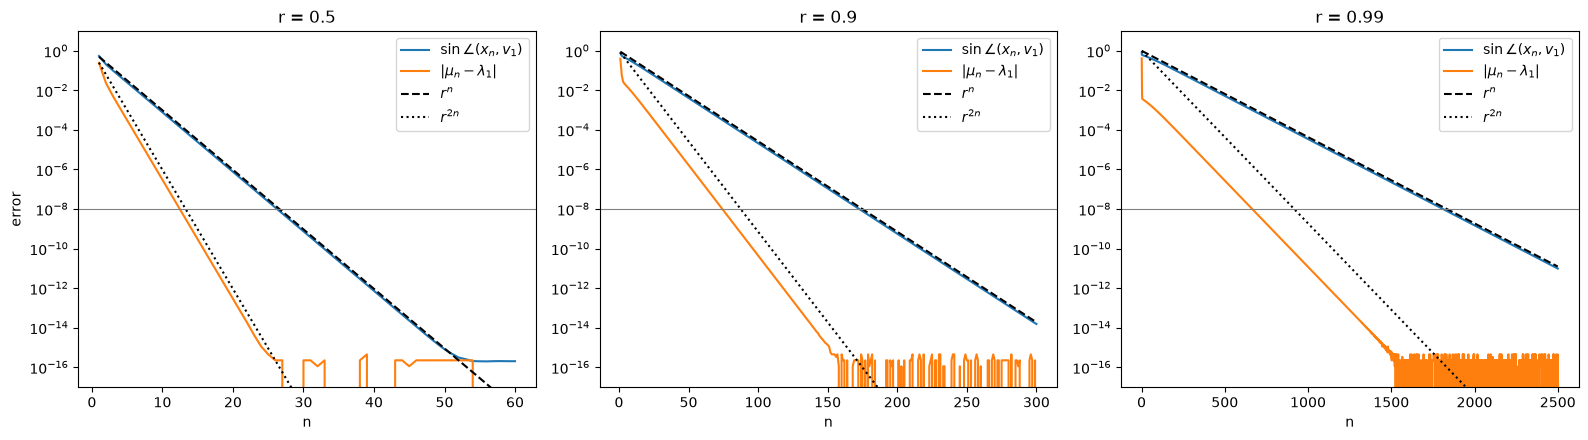

In [17]:
def power_errors(A, v1, lam1, n_steps, x0):
    # YOUR CODE HERE
    x = np.asarray(x0).copy()
    x = x / np.linalg.norm(x)

    vec_err = np.zeros(n_steps)
    val_err = np.zeros(n_steps)

    for n in range(n_steps):
        y = A @ x
        x = y / np.linalg.norm(y)
        mu = np.vdot(x, A @ x)

        vec_err[n] = sin_angle(x, v1)
        val_err[n] = abs(mu - lam1)

    return vec_err, val_err

k = 50
Q = random_orthogonal(k)
x0 = rng.standard_normal(k)
# YOUR CODE HERE: build A_r for r in (0.5, 0.9, 0.99), run power_errors, plot, report
r_values = (0.5, 0.9, 0.99)
n_steps = {0.5: 60, 0.9: 300, 0.99: 2500}
v1 = Q[:, 0]
lam1 = 1.0

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, r in zip(axes, r_values):
    eigs = np.concatenate(([1.0, r], np.linspace(-0.3 * r, 0.3 * r, k - 2)))
    A_r = Q @ np.diag(eigs) @ Q.T

    vec_err, val_err = power_errors(A_r, v1, lam1, n_steps[r], x0)
    n = np.arange(1, n_steps[r] + 1)

    predicted = int(np.ceil(np.log(1e-8) / np.log(r)))
    measured = np.argmax(vec_err <= 1e-8) + 1

    print(f'r = {r}: predicted {predicted} iterations, measured {measured} iterations')

    ax.semilogy(n, vec_err, label=r'$\sin\angle(x_n, v_1)$')
    ax.semilogy(n, val_err, label=r'$|\mu_n - \lambda_1|$')
    ax.semilogy(n, r ** n, 'k--', label=r'$r^n$')
    ax.semilogy(n, r ** (2 * n), 'k:', label=r'$r^{2n}$')
    ax.axhline(1e-8, color='gray', linewidth=0.8)
    ax.set_ylim(1e-17, 10)
    ax.set_title(f'r = {r}')
    ax.set_xlabel('n')
    ax.legend()

axes[0].set_ylabel('error')
plt.tight_layout()
plt.show()

**(c) Two observations to explain.**
1. For this symmetric $A_r$ the eigenvalue error falls like $r^{2n}$ — twice as fast as the eigenvector error. You do not need to prove this (Module 4 will), but describe what you see and say why it is good news for PageRank-style uses.
2. Now repeat (b) for $r = 0.9$ only, with $A = P\,\mathrm{diag}(\dots)\,P^{-1}$ built by `similar_matrix`, where $P = U\,\mathrm{diag}(s)\,V^\top$ has orthogonal $U, V$ and singular values $s$ spread logarithmically from $1$ to $10^{-3}$, so that $\kappa(P) = 10^3$. Did the **rate** change? Did anything else change? Relate this to the role of $\kappa(P)$ in Lecture 3.1.

In [15]:
# YOUR CODE HERE for (c)2

---
**Your answer here**

---

### 1.5 Reasons to fail
For each case below: explain *why* the method fails or slows down, give your own $3\times 3$ example, run `power_method` on it, and describe what you see (no convergence? convergence to the wrong thing? very slow convergence?). Look at `hist['res']` and `hist['mu']`, not only at the final output.

1. The dominant eigenvalues of a real matrix are a complex-conjugate pair.
2. $\lambda_1 = -\lambda_2$ (two real eigenvalues of equal modulus).
3. The dominant eigenvalue is defective: a Jordan block. *Hint:* it does converge — at what rate? Compare with the asymptotics $n^k|\lambda|^n$ from Lecture 3.1. Plot the eigenvector error, the eigenvalue error and the residual against $n$; they do **not** fall at the same rate. What does that tell you about trusting a small residual?
4. The starting vector has $c_1 = 0$. First run `power_method` with its defaults on $A = Q\,\mathrm{diag}(2,1,0.5)\,Q^\top$ (random orthogonal $Q$) and $\mathbf{x}_0 = \mathbf{q}_2$: why does it stop at once, and with what answer? Then switch the stopping test off (`tol=0`, `max_iter=120`) and compare two runs: $A = \mathrm{diag}(2, 1, 0.5)$ with $\mathbf{x}_0 = \mathbf{e}_2$, and $QDQ^\top$ with $\mathbf{x}_0 = \mathbf{q}_2$. They behave differently. Explain why, and predict roughly how many iterations the second one needs before it "notices" $\mathbf{v}_1$.

In [16]:
# YOUR CODE HERE: one experiment per case

---
**Your answer here**

---

---
## 2. Inverse iteration with a shift

### 2.1 The idea
If $A\mathbf{v} = \lambda\mathbf{v}$ then $(A - \mu I)^{-1}\mathbf{v} = (\lambda - \mu)^{-1}\mathbf{v}$. So the eigenvalue of $A$ **closest to the shift** $\mu$ becomes the *dominant* eigenvalue of $(A-\mu I)^{-1}$, and power iteration on $(A-\mu I)^{-1}$ finds it. The per-step rate is
$$
\frac{|\lambda_* - \mu|}{|\lambda_{**} - \mu|},
$$
where $\lambda_*$ is the closest eigenvalue and $\lambda_{**}$ the second-closest.

You never form $(A-\mu I)^{-1}$. Each step **solves** $(A - \mu I)\mathbf{y} = \mathbf{x}_{n-1}$. Factorise $A - \mu I = LU$ once with `scipy.linalg.lu_factor`, then call `scipy.linalg.lu_solve` at every step.

### 2.2 Implement `inverse_iteration`
Return the eigenvalue **of $A$** (the Rayleigh quotient $\mathbf{x}^*A\mathbf{x}$, not of the inverse), the unit eigenvector and the same history as before, with the same residual stopping rule applied to $A$.

In [ ]:
def inverse_iteration(A, mu, x0=None, tol=1e-10, max_iter=500):
    '''
    Eigenpair of A for the eigenvalue closest to the shift mu.
    One LU factorisation of A - mu I, reused at every step.
    Returns (lam, x, hist) as in power_method.
    '''
    # YOUR CODE HERE
    pass

**Question 2.2.** State the cost of your implementation in flops, to leading order, for a $k\times k$ matrix and $m$ iterations. Compare with (i) calling `np.linalg.solve(A - mu*I, x)` inside the loop and (ii) forming `inv(A - mu*I)` once and multiplying. Why is (ii) still worse than your version, even though its cost per step is also $O(k^2)$?

---
**Your answer here**

---

### 2.3 Find all eigenvalues of a test matrix
Let $D = \mathrm{diag}(0, 1, \dots, 9)$, let $P$ be a random $10\times10$ matrix, and $A = PDP^{-1}$ (use `similar_matrix`).

**(a)** Explain why the diagonal entries of $D$ are the eigenvalues of $A$ and the columns of $P$ are corresponding eigenvectors.

**(b)** With the shifts $\mu_j = j + 0.3$, $j = 0,\dots,9$, find all ten eigenpairs. Check each against the corresponding column of $P$ with `sin_angle`.

**(c)** Predict the per-step rate for $\mu = j + 0.3$ and for $\mu = j + 0.49$, then measure both for one $j$ of your choice from the history. Which eigenvalue does $\mu = j + 0.5$ find, and why is that shift a bad idea?

---
**Your answer here**

---

In [ ]:
D_vals = np.arange(10.)
P10 = rng.standard_normal((10, 10))
A10 = similar_matrix(D_vals, P10)
# YOUR CODE HERE

---
**Your answer here**

---

### 2.4 A shift that is *too* good
Take $\mu = 4 + 10^{-12}$. Compute $\kappa(A_{10} - \mu I)$ with `np.linalg.cond`. By everything you learned in Modules 1–2, solving with this matrix should be hopeless. Run `inverse_iteration` anyway and report the number of iterations and the accuracy of the eigenvector. Then explain, in your own words, why the huge condition number does no harm here. *(Hint: the solution $\mathbf{y}$ is badly wrong in length; in which direction is it wrong?)*

In [ ]:
# YOUR CODE HERE

---
**Your answer here**

---

---
## 3. Conclusions
In a few sentences: what did you learn, what was harder than expected, and which result surprised you? If you hit a wall you could not get past, describe it here **and** in your `README` — an explained wall is worth more at the defence than a clean output you cannot explain.

---
**Your answer here**

---

---
# ★ Extensions
Do **at most one** extension for the whole lab (A1, A2 here, or B1 in the Core B notebook). The point is awarded for **a defended finding**: end your extension with a short paragraph headed *Finding* that states what you found and why.

## ★ A1. The QR algorithm: what `np.linalg.eig` builds on
Starting from $A_1 = A$, repeat: factor $A_k = Q_kR_k$, set $A_{k+1} := R_kQ_k$. Under mild assumptions $A_k$ tends to an upper-triangular matrix with the eigenvalues of $A$ on the diagonal.

1. Show that every $A_{k+1}$ is similar to $A_k$ (write $A_{k+1}$ as $Q_k^\top A_k Q_k$), so the eigenvalues never change.
2. Implement the **unshifted** method (`np.linalg.qr` is allowed). Stop when the largest entry below the diagonal is below $10^{-10}\|A\|_F$. Run it on $A = Q\,\mathrm{diag}(1,2,\dots,10)\,Q^\top$. Count the iterations. Predict that count from the ratios $\lambda_{i+1}/\lambda_i$ before you run it. *(Hint: the unshifted method behaves like power iteration on all columns at once.)*
3. Implement a **shifted** version with deflation: on the active $m\times m$ block, use $\mu = a_{mm}$, factor $A_k - \mu I = QR$, set $A_{k+1} = RQ + \mu I$; when $|a_{m,m-1}|$ is negligible, accept $a_{mm}$ and continue with the leading $(m-1)\times(m-1)$ block. Count the total iterations on the same $A$, and record $|a_{m,m-1}|$ step by step for one eigenvalue. How fast does it fall — do the correct digits roughly double, or more?
4. Run the unshifted method on a real matrix whose dominant eigenvalues are a complex pair. What does $A_k$ look like after many steps? Connect this with failure case 1 of §1.5.

In [ ]:
# YOUR CODE HERE

## ★ A2. Stable, yet it grows: non-normal iterated maps
An iterated map $\mathbf{x}_{n+1} = A\mathbf{x}_n$ with spectral radius $\rho(A) < 1$ always tends to $\mathbf{0}$. It need **not** get there monotonically. This matters whenever a linear recurrence is called "stable" because its eigenvalues are inside the unit circle — a linear RNN or an autoregressive model, for example.

1. Take $A = \begin{pmatrix} 0.95 & 10 \\ 0 & 0.9\end{pmatrix}$. Plot $\|A^n\|_2$ for $n = 0,\dots,200$ together with $\rho(A)^n$ and the bound $\kappa(P)\,\rho(A)^n$ from Lecture 3.1 ($P$ the eigenvector matrix; here you may use `np.linalg.eig`). Find the peak of $\|A^n\|_2$ and the $n$ where it happens.
2. Derive $A^n$ in closed form for this triangular $A$ and use it to explain the peak.
3. Repeat for the $20\times20$ bidiagonal matrix with $0.9$ on the diagonal and $1$ on the superdiagonal. How large does $\|A^n\|_2$ get before it decays? Why is $\kappa(P)$ useless as a bound here?

In [ ]:
# YOUR CODE HERE